# Absolute P_L(p) with an anchored BAR ladder

Install `pip install '.[notebooks,matching,codes]'`. This tutorial follows the workflow curve's toric d=3 and d=5 bit-flip setting and ladder [0.30, 0.26, 0.22]. The MWPM decoder is fixed across all rungs; the failure set therefore stays fixed. The associated paper is in preparation.

In [1]:
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image, display
from mcmc4qec import spawn_seeds
QUICK = os.environ.get("MCMC4QEC_QUICK") == "1"
SEED = 2026
print(f"quick={QUICK}; root seed={SEED}")

quick=False; root seed=2026


At the first rung, independent direct Monte Carlo supplies an absolute anchor. BAR uses adjacent failure-conditioned ensembles to carry that probability down the ladder. An MC anchor must have **positive observed failures**; this notebook checks and reports the count. Coarse spacing can give poor overlap and unstable estimates even when every state has positive probability. At these finite bit-flip probabilities, all states have positive support, so coarse spacing alone does not cause `OverlapError`. That exception means the observed samples lack bidirectional support, which matters especially when a model has parameter-dependent zero-probability states. Add intermediate rungs or increase sampling to improve overlap.

The recorded default d=3 study observed minimum BAR overlap around 0.48 with finite support at every sampled state. Its interval disagreement is therefore not evidence of missing support; see the [controlled sensitivity study](../docs/bar_sensitivity_ja.md).

In [2]:
from mcmc4qec import IndependentBitFlip, Problem, SamplingConfig, direct_mc, estimate_logical_error, OverlapError
from mcmc4qec.adapters import matching_from_check_matrix
from mcmc4qec.codes import make_toric_code
ladder = [0.30, 0.26, 0.22]
seeds = iter(spawn_seeds(SEED, 8))
if QUICK:
    print("Quick mode checks the workflow; it does not guarantee research precision.")
curves = {}
for distance in (3, 5):
    code = make_toric_code(distance)
    decoder = matching_from_check_matrix(code.hz, logical_map=code.lz, identifier=f"toric-d{distance}-mwpm")
    problem = Problem(code.bit_flip_model(), IndependentBitFlip(code.n), decoder)
    anchor = direct_mc(problem, ladder[0], trials=200 if QUICK else 1500, seed=next(seeds))
    print(f"d={distance} anchor failures={anchor.failures}/{anchor.trials}")
    if not 0 < anchor.failures < anchor.trials:
        raise RuntimeError("MC anchor needs observed failures and successes; increase its fixed trial count")
    try:
        bar = estimate_logical_error(problem, ladder, anchor=anchor,
            config=SamplingConfig(chains=4, samples=40 if QUICK else 600,
                                  burn_in=12 if QUICK else 180),
            seed=next(seeds), bootstrap_replicates=10 if QUICK else 30)
    except OverlapError as exc:
        raise RuntimeError("Adjacent ladder rungs lack observed overlap; refine the ladder") from exc
    check_estimates, check_intervals = [], []
    for index, (rung, estimate, interval) in enumerate(zip(ladder, bar.estimates, bar.intervals)):
        check = anchor if index == 0 else direct_mc(problem, rung,
            trials=180 if QUICK else 1200, seed=next(seeds))
        check_estimates.append(check.estimate)
        check_intervals.append(check.interval)
        if index == 0:
            print(f"  p={rung:.2f} BAR P_L={estimate:.5f} interval={interval}; "
                  f"MC anchor={check.estimate:.5f} interval={check.interval}")
            continue
        intervals_overlap = (None if interval is None else
            max(interval[0], check.interval[0]) <= min(interval[1], check.interval[1]))
        print(f"  p={rung:.2f} BAR P_L={estimate:.5f} interval={interval}; "
              f"independent direct MC={check.estimate:.5f} interval={check.interval}; "
              f"intervals overlap={intervals_overlap}")
        if intervals_overlap is None:
            print("  WARNING: BAR interval unavailable; inspect sampled overlap and bootstrap blocks.")
        elif not intervals_overlap:
            print("  WARNING: intervals do not overlap; investigate mixing, ladder design, and finite-MC variation.")
    curves[distance] = (bar.estimates, bar.intervals, check_estimates, check_intervals)

d=3 anchor failures=1062/1500


  p=0.30 BAR P_L=0.70800 interval=(0.6853602074703797, 0.7313876623361794); MC anchor=0.70800 interval=(0.6844822673810914, 0.730455089439313)


  p=0.26 BAR P_L=0.62587 interval=(0.6007669006204029, 0.6520276603902133); independent direct MC=0.67583 interval=(0.6488259327140901, 0.7017185654072814); intervals overlap=True


  p=0.22 BAR P_L=0.53447 interval=(0.5055163266489403, 0.5650849390034506); independent direct MC=0.59917 interval=(0.5711650330352703, 0.6265354185118538); intervals overlap=False


d=5 anchor failures=1105/1500


  p=0.30 BAR P_L=0.73667 interval=(0.7147114705124114, 0.7592963037079925); MC anchor=0.73667 interval=(0.713793380870001, 0.7583308552557799)


  p=0.26 BAR P_L=0.69730 interval=(0.662076727542651, 0.7344051579925938); independent direct MC=0.74417 interval=(0.718727478611589, 0.7680475827607419); intervals overlap=True


  p=0.22 BAR P_L=0.64651 interval=(0.5974877785530374, 0.6995548717875695); independent direct MC=0.69917 interval=(0.6726163521319376, 0.7244458992946398); intervals overlap=True


The first point inherits the MC anchor interval; it is not an independent check. We compare later BAR intervals with independent direct-MC check points. If a bootstrap BAR interval is unavailable, overlap cannot be judged from intervals. Non-overlap calls for investigation of mixing, ladder design, and finite-MC variation rather than an automatic accuracy claim. Quick mode verifies execution, not research precision. Later BAR intervals assume adequate chain mixing and block length; they do not include an unmeasured mixing bias. `sample_faulty` frequencies alone are not absolute `P_L`. We keep the decoder fixed because a p-dependent BP-OSD decoder changes the failure set. The explicit `p_dependent_decoder_approx` mode omits that change from its interval.

For the default d=3, p=0.22 problem, exact enumeration gives `P_L = 0.6026625647`. With workflow seed 2026, the BAR interval misses this truth while the independent MC interval covers it. In the exploratory 20-seed study, coverage was **13/20 for BAR** and **20/20 for independent MC**; the corresponding Wilson intervals are wide, so these are not calibrated 95% guarantees. Default block length 8 was shorter than the median maximum weight IAT of 35.69. Increasing block length widened intervals, but did not remove seed 2026's point-estimate discrepancy. Vary samples, burn-in, block length, ladder, and starting states separately, and compare with exact truth or independent MC where feasible. Longer chains can help but do not by themselves establish mixing. See the [study and its limitations](../docs/bar_sensitivity_ja.md); these short notebook runs do not guarantee research precision.

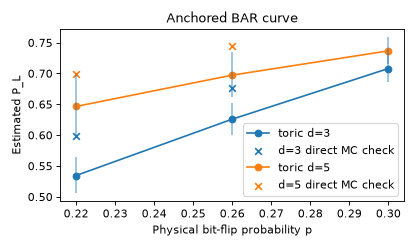

In [3]:
fig, ax = plt.subplots(figsize=(5.2, 3.1))
for distance, (estimates, intervals, check_estimates, check_intervals) in curves.items():
    ax.plot(ladder, estimates, marker="o", label=f"toric d={distance}")
    for p_rung, estimate, interval in zip(ladder, estimates, intervals):
        if interval is not None:
            ax.vlines(p_rung, interval[0], interval[1], alpha=.5)
    ax.scatter(ladder[1:], check_estimates[1:], marker="x", label=f"d={distance} direct MC check")
ax.set(xlabel="Physical bit-flip probability p", ylabel="Estimated P_L", title="Anchored BAR curve")
ax.legend()
fig.tight_layout()
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=80)
display(Image(data=buffer.getvalue()))
plt.close(fig)